In [1]:
import numpy as np
np.random.seed(42)

import warnings
warnings.filterwarnings("ignore")

In [2]:
from pathlib import Path

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

**Первый датасет**

*USA top 900+ Companies stock historic dataset* - дневные котировки акций 900+ компаний США, отдельный CSV на компанию (Date, Open, High, Low, Close, Volume, Dividends, Stock Splits). Я взяла акции Apple

In [3]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

df_apple = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "anukaggle81/usa-top-900-historic-dataset",
    "Apple.csv",
)
df_apple.head()

,Unnamed: 0,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,0,1980-12-12,0.098726,0.099155,0.098726,0.098726,469033600,0.0,0.0
1,1,1980-12-15,0.094005,0.094005,0.093575,0.093575,175884800,0.0,0.0
2,2,1980-12-16,0.087136,0.087136,0.086707,0.086707,105728000,0.0,0.0
3,3,1980-12-17,0.088853,0.089282,0.088853,0.088853,86441600,0.0,0.0
4,4,1980-12-18,0.091429,0.091858,0.091429,0.091429,73449600,0.0,0.0


Взяла последний непрерывный отрезок из 1000 торговых дней. Использовала доходности, а не сырые цены, потому что цена акции на всей истории имеет выраженный растущий тренд. Доходности же стационарны и статистически ближе к броуновскому движению, что и является целью выбора этого типа ряда в лабораторной

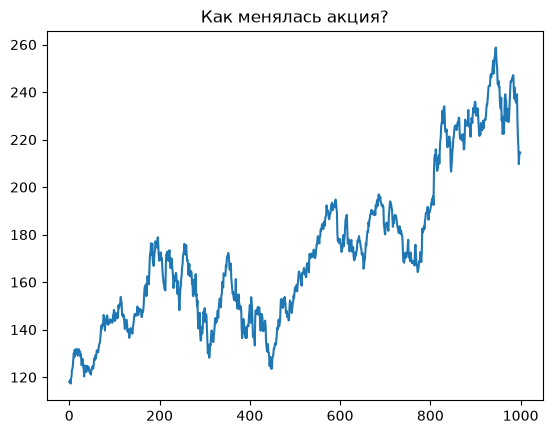

In [4]:
import pandas as pd
df_apple = df_apple.drop(columns=["Unnamed: 0"])

df_apple["Date"] = pd.to_datetime(df_apple["Date"])
df_apple = df_apple.sort_values("Date").reset_index(drop=True)

series = df_apple["Close"].tail(1000).reset_index(drop=True)
series.plot(title="Как менялась акция?");

Видно явный тренд - акция росла со 115 до 260 за эти 1000 дней. Это нужно только для наглядности как вела себя акция

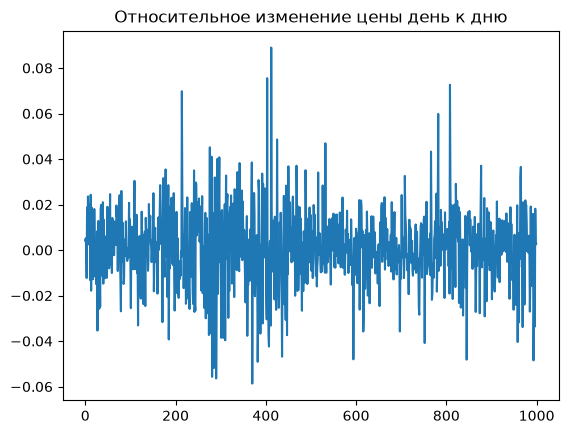

In [5]:
returns = df_apple["Close"].pct_change().dropna().tail(1000).reset_index(drop=True)
returns.plot(title="Относительное изменение цены день к дню");

Тренда нет, колебания идут вокруг нуля, амплитуда более-менее одинаковая на всем периоде. Это стационарный ряд без явной структуры

*Тест на случайное блуждание*

In [6]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(returns.values)

print(f"ADF statistic: {adf_result[0]:.3f}")
print(f"p-value: {adf_result[1]:.4f}")
print(f"Число использованных лагов: {adf_result[2]}")
print(f"Число наблюдений: {adf_result[3]}")
print(f"Критические значения: {adf_result[4]}")

ADF statistic: -31.194
p-value: 0.0000
Число использованных лагов: 0
Число наблюдений: 999
Критические значения: {'1%': np.float64(-3.4369127451400474), '5%': np.float64(-2.864437475834273), '10%': np.float64(-2.568312754566378)}


Тестовая статистика ADF (−31.194) многократно превышает по модулю критическое значение для самого строгого уровня значимости (1%: −3.437), что подтверждает стационарность ряда доходностей с исключительно высокой надежностью. Еще было выбрано 0 лагов для построения тестовой регрессии - это дополнительно подтверждает отсутствие значимой автокорреляционной структуры в ряде

*Проверка нормальности распределения*

In [7]:
from scipy import stats

shapiro_stat, shapiro_p = stats.shapiro(returns.values)
print(f"Тест Шапиро-Уилка: statistic={shapiro_stat:.3f}, p-value={shapiro_p:.2e}")

Тест Шапиро-Уилка: statistic=0.976, p-value=1.00e-11


Тест Шапиро-Уилка показывает статистически значимое отклонение распределения доходностей от нормального (p<0.001), что согласуется с эмпирически известным свойством финансовых рядов - наличием тяжелых хвостов

* Сезонная декомпозиция

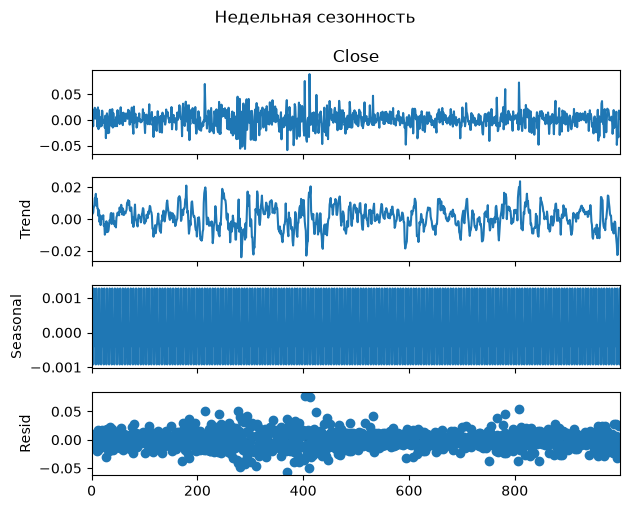

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

result = seasonal_decompose(returns, model='additive', period=5)
fig = result.plot()
fig.suptitle("Недельная сезонность", y=1.05)
plt.show()

Seasonal-компонента очень мала, без содержательного паттерна. Trend тоже колеблется вокруг нуля без выраженного направления. Вывод: недельной сезонности нет

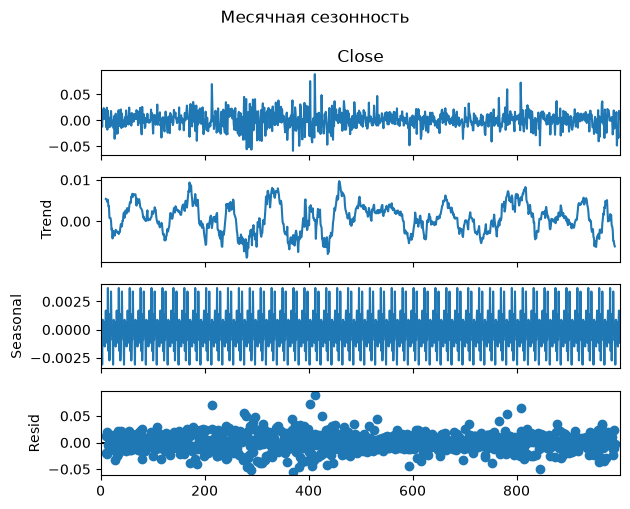

In [9]:
result = seasonal_decompose(returns, model='additive', period=21)
fig = result.plot()
fig.suptitle("Месячная сезонность", y=1.05)
plt.show()

Seasonal чуть больше по амплитуде по сравнению с недельной сезонностью, но все еще очень мала относительно исходного ряда. Trend стал более гладким (сглаживание на большем окне убирает часть шума), но по-прежнему без устойчивого направления. Вывод: месячной сезонности тоже нет

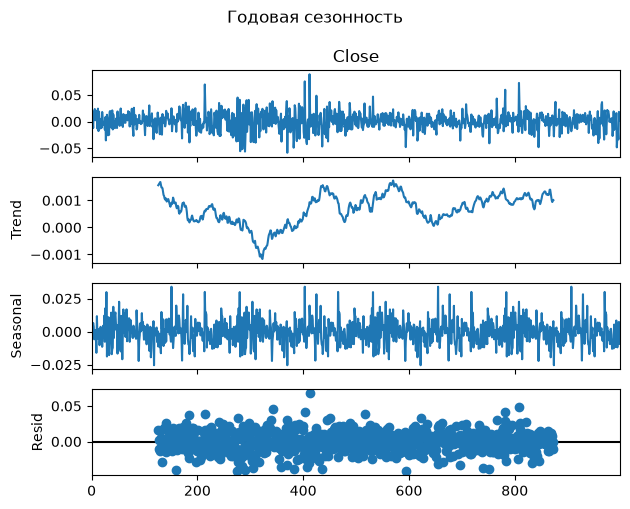

In [10]:
result = seasonal_decompose(returns, model='additive', period=252)
fig = result.plot()
fig.suptitle("Годовая сезонность", y=1.05)
plt.show()

Здесь заметны два важных отличия:

1. Trend сжался до очень узкого диапазона. Это ожидаемо, потому что на окне в 252 точки при ряде из 1000 остается мало полных циклов для устойчивой оценки тренда (края ряда обрезаны — заметно, что Trend и Resid начинаются не с нуля, а примерно с 130-й точки)
2. Seasonal почти сравнялась с масштабом самого ряда. Но это не значит, что нашлась настоящая годовая сезонность — при большом периоде на выборке всего в 1000 точек метод просто переобучается на редких повторяющихся паттернах и статистический шум ошибочно интерпретируется как сезонность

Сезонная декомпозиция при периодах 5, 21 и 252 подтверждает отсутствие устойчивой сезонной структуры в доходностях Apple. Рост амплитуды Seasonal-компоненты при period=252 объясняется недостатком данных для надежной оценки на таком масштабе, а не наличием реальной годовой периодичности. Это согласуется с гипотезой случайного блуждания

* Преобразование Фурье

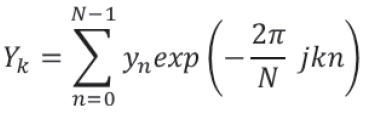

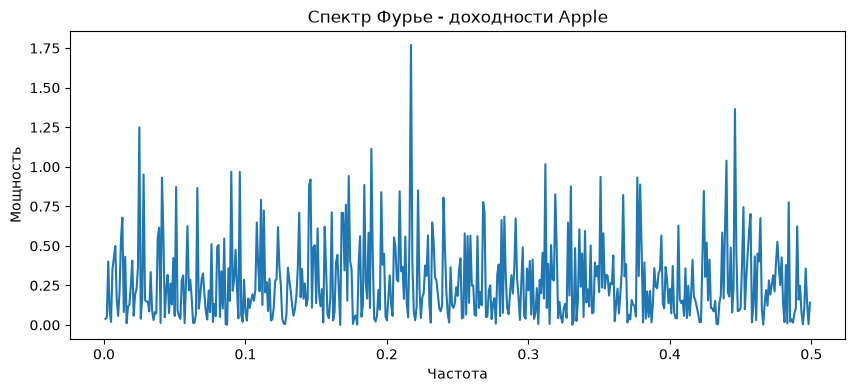

In [11]:
# np.fft.fft вычисляет эту сумму для всех k эффективным алгоритмом (БПФ)
# Результат - комплексные числа Y_k
fft_vals = np.fft.fft(returns.values)
# Переводим индекс k в нормированную частоту (k/N)
freqs = np.fft.fftfreq(len(returns))
# Берем модуль комплексного Y_k (амплитуду) и возводим в квадрат — получаем мощность на данной частоте для стандартного анализа спектра
power = np.abs(fft_vals)**2

# Строим только положительные частоты (отрицательная половина спектра — зеркальное отражение, дублирует информацию)
plt.figure(figsize=(10,4))
plt.plot(freqs[freqs > 0], power[freqs > 0])
plt.xlabel("Частота")
plt.ylabel("Мощность")
plt.title("Спектр Фурье - доходности Apple")
plt.show()

Спектр Фурье доходностей Apple не содержит доминирующих пиков. Мощность распределена относительно равномерно по всему диапазону частот, что характерно для белого шума. Отдельные локальные максимумы (например, на частоте примерно 0.2) статистически незначимы на фоне общего уровня шума и не образуют устойчивой периодической структуры. Это согласуется с результатами об отсутствии сезонности и подтверждает гипотезу случайного блуждания

* Автокорреляционная функция

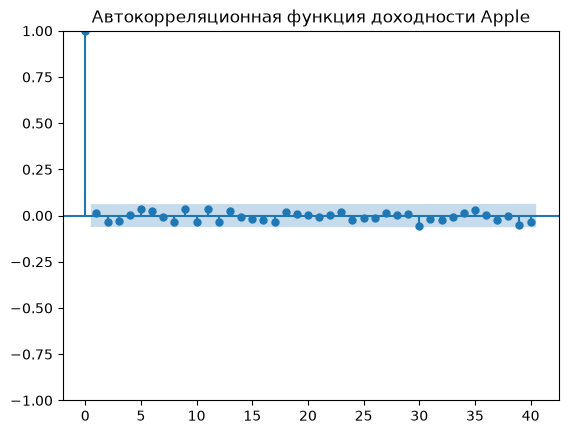

In [12]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(returns, lags=40)
plt.title("Автокорреляционная функция доходности Apple")
plt.show()

Корреляция ряда с самим собой без сдвига по времени равна кдинице - это ожидаемо, ряд всегда идеально коррелирует сам с собой

Все остальные наблюдения близки к нулю и находятся внутри голубой доверительной области (95% доверительный интервал). Это значит, что ни на одном из 40 лагов автокорреляция статистически не отличима от нуля.

Вывод: прошлые значения доходности не помогают предсказать будущие значения ни на каком из проверенных горизонтов (от 1 до 40 дней). Нет линейной памяти в ряде. То есть прошлые доходности не предсказывают будущие

*Теорема Такенса*

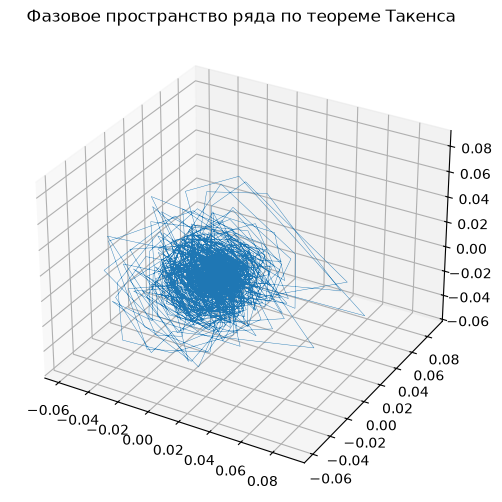

In [13]:
lag = 1
embed_dim = 3
X = np.array([returns.values[i:i+embed_dim] for i in range(len(returns)-embed_dim)])

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(projection='3d')
ax.plot(X[:,0], X[:,1], X[:,2], lw=0.3)
ax.set_title("Фазовое пространство ряда по теореме Такенса");

Видно плотный, бесструктурный клубок без какой-либо выраженной формы, воронки, спирали или другого узнаваемого паттерна (если бы они были, это был бы сигнал, что за кажущимся шумом скрывается низкоразмерная детерминированная динамика, например, как у аттрактора Лоренца)

Отсутствие такой структуры означает, что доходности Apple не порождаются детерминированной (в том числе хаотической) системой с низкой размерностью фазового пространства

Это визуально согласуется со всеми предыдущими результатами: ряд ведет себя как стохастический процесс без скрытого детерминированного механизма, а не как хаотическая, но в принципе предсказуемая на коротком горизонте система

* Показатель Хёрста и размерность Хаусдорфа

  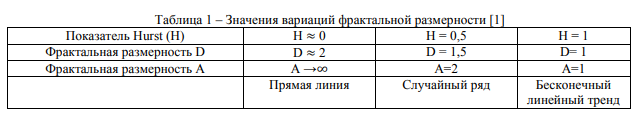

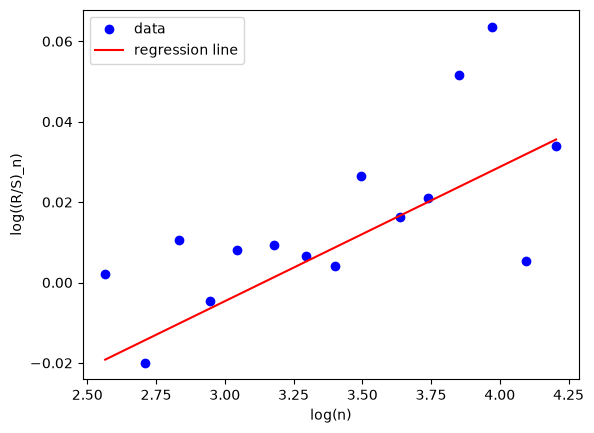

Показатель Хёрста: 0.533
Размерность Хаусдорфа: 1.467


In [14]:
# nolds 0.6.3 на Python 3.11 падает при импорте своих встроенных датасетов,
# поэтому на время импорта подсказываем, где их искать
from importlib import resources
_files = resources.files
resources.files = lambda p: _files("nolds") if p == "nolds.datasets" else _files(p)
import nolds
resources.files = _files

H = nolds.hurst_rs(returns.values, debug_plot=True)
D_hausdorff = 2 - H

print(f"Показатель Хёрста: {H:.3f}")
print(f"Размерность Хаусдорфа: {D_hausdorff:.3f}")

Точки данных не идеально ложатся на прямую, есть заметный разброс, что нормально для реальных финансовых данных

Красная линия регрессии - наклон, дающий итоговую оценку Хёрста

(0 ≤ H < 0.5 — антиперсистентность/розовый шум; 

H = 0.5 — белый шум/случайность; 

0.5 < H ≤ 1 — персистентность/тренды)

Наше значение пограничное, но чуть выше 0.5, что формально указывает на очень слабую персистентность (положительную автокорреляцию), однако настолько близко к 0.5, что практически неотличимо от чистого случайного блуждания в пределах погрешности метода

Размерность Хаусдорфа D=1.467 практически совпадает с эталонным значением для случайного ряда (D=1.5 при H=0.5, согласно таблице Некрасовой). Это визуально подтверждает фрактальную природу траектории доходностей, характерную для броуновского движения/случайного блуждания.

* Показатель Ляпунова и энтропия Колмогорова-Синая

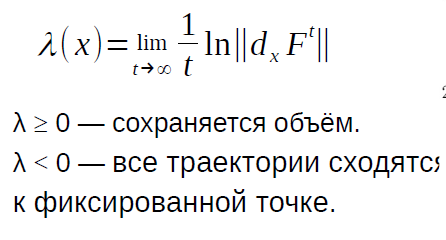

Согласно теореме Песина, для динамических систем KS-энтропия равна сумме положительных 
показателей Ляпунова

In [15]:
# nolds.lyap_r реализует алгоритм Розенштайна:
# 1) находим ближайших соседей в реконструированном фазовом пространстве
# 2) отслеживаем расхождение траекторий во времени
# 3) угол наклона log(расхождения) от времени = показатель Ляпунова
lyap = nolds.lyap_r(returns.values)
print(f"Показатель Ляпунова (старший): {lyap:.4f}")

# По теореме Песина: KS-энтропия примерно равна сумме положительных показателей Ляпунова
# (для 1D ряда — просто сам показатель, если положительный)
ks_entropy = max(lyap, 0)
print(f"Энтропия Колмогорова-Синая (по теореме Песина): {ks_entropy:.4f}")

Показатель Ляпунова (старший): 0.0087
Энтропия Колмогорова-Синая (по теореме Песина): 0.0087


Показатель Ляпунова 0.0087 формально положителен, но его малая величина в сочетании с отсутствием структуры в реконструированном фазовом пространстве (график Такенса) говорит о том, что ряд не описывается низкоразмерной хаотической динамикой. Малое положительное значение корее артефакт применения метода к стохастическому процессу, чем признак истинного детерминированного хаоса

Энтропия Колмогорова-Синая (0.0087), рассчитанная через теорему Песина, формально мала, что для детерминированной системы указывало бы на медленную потерю информации о начальном состоянии и, соответственно, высокую предсказуемость. Но для стохастического процесса, каким является ряд доходностей Apple, такая интерпретация неприменима напрямую. "Информация о детерминированном начальном состоянии" здесь теряет смысл, поскольку эволюция ряда не описывается детерминированным законом. Низкое значение KS-энтропии в данном случае не признак предсказуемости, а, как и показатель Ляпунова, отражает отсутствие детерминированной структуры

* Энтропия перестановок

In [16]:
import antropy as ant

for order in [3, 4, 5, 6]:
    pe = ant.perm_entropy(returns.values, order=order, normalize=True)
    print(f"order={order}: Энтропия перестановок = {pe:.4f}")

order=3: Энтропия перестановок = 0.9997
order=4: Энтропия перестановок = 0.9976
order=5: Энтропия перестановок = 0.9875
order=6: Энтропия перестановок = 0.9368


Энтропия перестановок остается стабильно высокой при order от 3 до 6, что подтверждает устойчивость вывода о случайности структуры ряда на разных масштабах анализа. Небольшое снижение при увеличении order объясняется ограниченным размером выборки относительно растущего числа возможных перестановок (720 при order=6), а не наличием скрытой предсказуемой структуры

In [17]:
pe = ant.perm_entropy(returns.values, order=3, normalize=True)  # основное значение для таблицы

* Сводная таблица

In [18]:
import pandas as pd

results = pd.DataFrame({
    "Ряд": ["Apple returns"],
    "ADF p-value": [adf_result[1]],
    "Shapiro p-value": [shapiro_p],
    "Hurst": [H],
    "Hausdorff dim": [D_hausdorff],
    "Lyapunov": [lyap],
    "KS entropy": [ks_entropy],
    "Permutation entropy": [pe],
})
results

,Ряд,ADF p-value,Shapiro p-value,Hurst,Hausdorff dim,Lyapunov,KS entropy,Permutation entropy
0,Apple returns,0.0,1.004108e-11,0.533396,1.466604,0.008695,0.008695,0.999675


Комплексный анализ временного ряда доходностей Apple демонстрирует: ряд статистически неотличим от случайного блуждания. Показатель Хёрста (0.533) и соответствующая размерность Хаусдорфа (1.467) практически точно совпадают с эталонными значениями для случайного процесса. Отсутствие сезонности (декомпозиция), отсутствие доминирующих частот (Фурье), отсутствие значимой автокорреляции (ACF) и отсутствие структуры в фазовом пространстве (Такенс) исключают наличие как периодической, так и детерминированной динамики. Энтропия перестановок (0.9997) близка к теоретическому максимуму, подтверждая максимальную локальную непредсказуемость. Единственное отклонение от "идеального" случайного процесса - распределение доходностей не является строго нормальным (тест Шапиро-Уилка), что согласуется с известным эмпирическим фактом о тяжелых хвостах в финансовых рядах (эффект Мандельброта).

Практический вывод о предсказуемости: доходности Apple на дневном горизонте не содержат извлекаемого предсказуемого сигнала, то есть прошлые значения ряда не дают статистически значимой информации о будущих.

**Второй датасет**

*MTA Subway Hourly Ridership (NYC)* - данные о почасовом пассажиропотоке метро Нью-Йорка за 2024 год получены из репозитория xinychen/integers (файл NYC_subway_mob_24.npz), в котором агрегированы официальные данные из data.ny.gov

In [19]:
import urllib.request
import numpy as np

url = "https://github.com/xinychen/integers/raw/main/Manhattan-subway/NYC_subway_mob_24.npz"
urllib.request.urlretrieve(url, DATA_DIR / "NYC_subway_mob_24.npz")

data = np.load(DATA_DIR / "NYC_subway_mob_24.npz")
print(data.files)

['arr_0']


In [20]:
tensor = data['arr_0']
print(f"Форма: {tensor.shape}")

Форма: (263, 8784)


In [21]:
# Суммируем по станциям, чтобы получить один агрегированный часовой ряд
hourly_total = tensor.sum(axis=0)
print(f"Длина итогового ряда: {len(hourly_total)}")

Длина итогового ряда: 8784


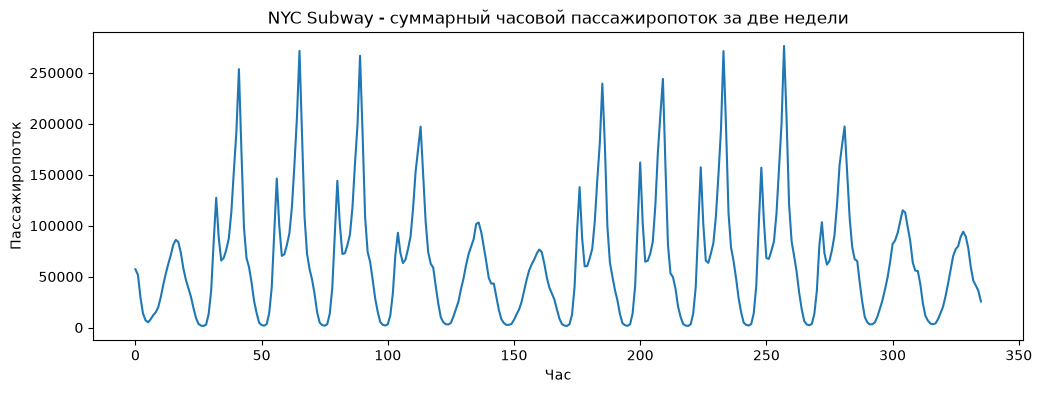

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.plot(hourly_total[:24*14])  # Берем первые 2 недели, чтобы проверить на суточную/недельную периодичность
plt.title("NYC Subway - суммарный часовой пассажиропоток за две недели")
plt.xlabel("Час")
plt.ylabel("Пассажиропоток")
plt.show()

Виден суточный цикл с 14 хорошо различимыми пиками: по одному на каждый день. Амплитуда пиков неоднородна: будние дни дают пики 230-270 тыс. пассажиров, а в выходные пиковая нагрузка заметно ниже: около 100 тыс. Это подтверждает наличие двух наложенных периодичностей: суточной и недельной

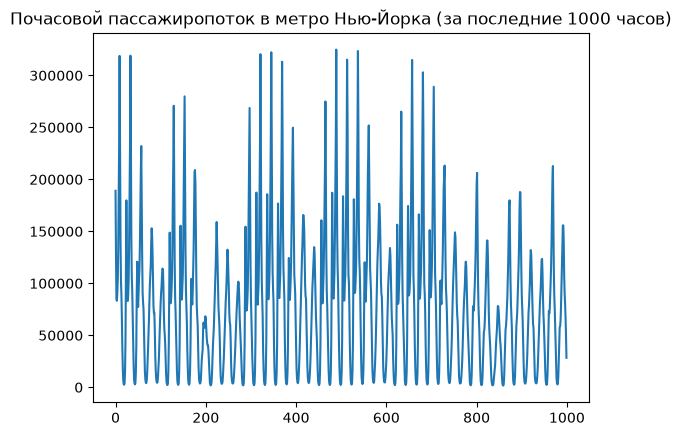

In [23]:
import pandas as pd

series_subway = pd.Series(hourly_total[-1000:]).reset_index(drop=True)
series_subway.plot(title="Почасовой пассажиропоток в метро Нью-Йорка (за последние 1000 часов)");

На более длинном горизонте та же суточная структура сохраняется устойчиво на всем протяжении ряда. Пики регулярно повторяются каждые 24 часа без затухания. Видна модуляция амплитуды пиков на недельном масштабе: группы из 5 высоких пиков (будни) чередуются с более низкими (выходные), что визуально согласуется с наблюдением на первом графике. Это дает основание ожидать, что дальнейший анализ должен выявить два выраженных пика периодичности на частотах, соответствующих 24 часам и 168 часам

*Тест на случайное блуждание*

In [24]:
adf_result = adfuller(series_subway.values)

print(f"ADF statistic: {adf_result[0]:.3f}")
print(f"p-value: {adf_result[1]:.4f}")
print(f"Число использованных лагов: {adf_result[2]}")
print(f"Число наблюдений: {adf_result[3]}")
print(f"Критические значения: {adf_result[4]}")

ADF statistic: -1.916
p-value: 0.3244
Число использованных лагов: 22
Число наблюдений: 977
Критические значения: {'1%': np.float64(-3.43706091543889), '5%': np.float64(-2.8645028204932483), '10%': np.float64(-2.568347558984588)}


ADF-тест (p=0.32 ≫ 0.05) не отвергает гипотезу единичного корня. Тестовая статистика (−1.916) по модулю заметно меньше даже самого мягкого критического значения (10%: −2.568), то есть не приближается ни к одному из порогов стационарности. Это объясняется выраженной сезонной компонентой в данных, которую стандартный ADF-тест интерпретирует как нестационарность, поскольку не учитывает периодическую структуру напрямую.

Показательно, что тест автоматически выбрал 22 лага для построения тестовой регрессии. Это напрямую отражает наличие сильной автокорреляционной зависимости: тесту потребовалось учесть значения вплоть до 22 часов назад, чтобы адекватно описать структуру ряда

*Проверка нормальности распределения*

In [25]:
shapiro_stat, shapiro_p = stats.shapiro(series_subway.values)
print(f"Тест Шапиро-Уилка: statistic={shapiro_stat:.3f}, p-value={shapiro_p:.2e}")

Тест Шапиро-Уилка: statistic=0.913, p-value=1.68e-23


Тест Шапиро-Уилка показывает сильное отклонение распределения пассажиропотока от нормального. Это ожидаемый результат для ряда с выраженной суточной цикличностью

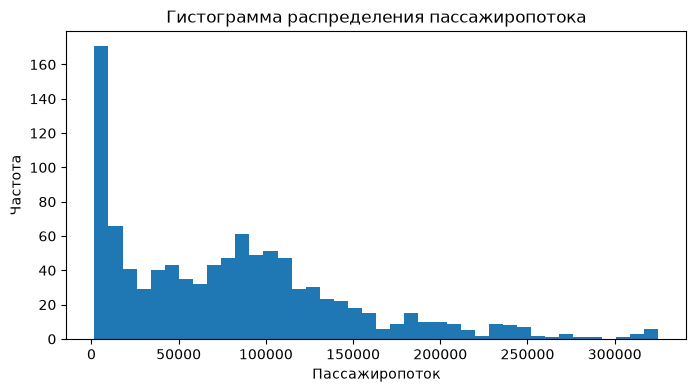

In [26]:
plt.figure(figsize=(8,4))
plt.hist(series_subway.values, bins=40)
plt.title("Гистограмма распределения пассажиропотока")
plt.xlabel("Пассажиропоток")
plt.ylabel("Частота")
plt.show()

Гистограмма показывает выраженную асимметрию: резкий пик наблюдений у минимальных значений (ночные часы с низким трафиком) и длинный правый хвост, простирающийся до пиковых значений часов пик. Такая форма далека от нормального распределения и статистически подтверждается тестом Шапиро-Уилка

* Сезонная декомпозиция

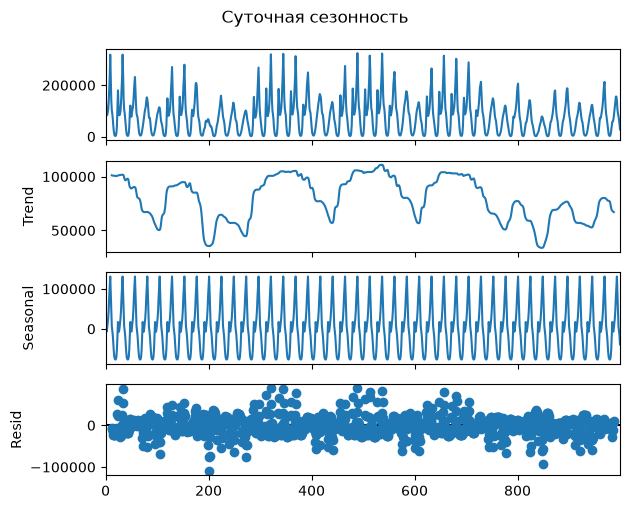

In [27]:
result = seasonal_decompose(series_subway, model='additive', period=24)
fig = result.plot()
fig.suptitle("Суточная сезонность", y=1.05)
plt.show()

Seasonal-компонента четкая и регулярная, с амплитудой колебаний ±100 тыс, сопоставима по масштабу с самим исходным рядом. Trend плавно колеблется в диапазоне 30-110 тыс, отражая изменение общего уровня загруженности метро на протяжении недель. Resid содержит заметный разброс (±100 тыс в отдельных точках). Значит, чистая суточная модель объясняет не всю структуру, часть дисперсии остается неучтенной

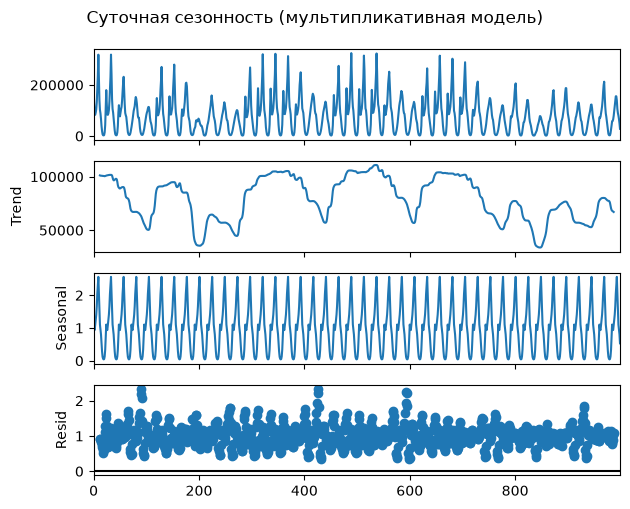

In [28]:
result_mult = seasonal_decompose(series_subway, model='multiplicative', period=24)
fig = result_mult.plot()
fig.suptitle("Суточная сезонность (мультипликативная модель)", y=1.05)
plt.show()

Seasonal-компонента здесь выражена как мультипликативный коэффициент около 1 (колеблется от 0 до 2.5), то есть фактические значения умножаются на этот коэффициент, а не складываются. Общий Trend идентичен аддитивной модели. Resid в мультипликативной модели колеблется вокруг 1 более равномерно на всем диапазоне, без явных выбросов, которые были в аддитивной модели. Это может говорить о том, что мультипликативная модель лучше описывает данные, так как амплитуда суточных колебаний действительно растет/падает пропорционально общему уровню трафика (в будни колебания больше, в выходные меньше), что и предполагает мультипликативная, а не аддитивная модель

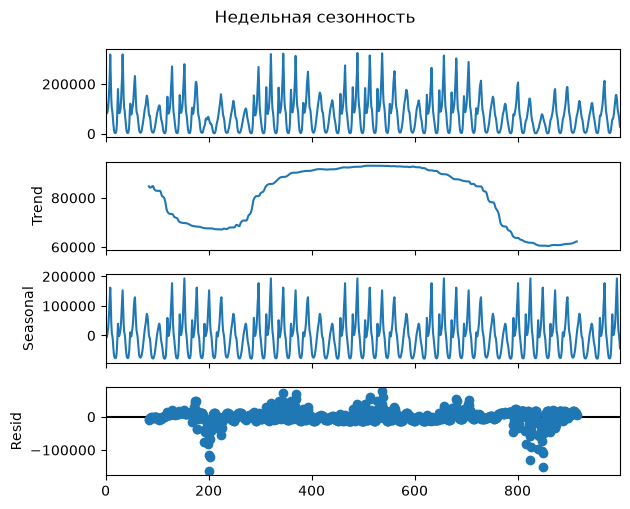

In [29]:
result = seasonal_decompose(series_subway, model='additive', period=168)
fig = result.plot()
fig.suptitle("Недельная сезонность", y=1.05)
plt.show()

Trend сглаженный, показывает плавный рост загруженности метро с 65 тыс до 100 тыс и последующий спад обратно. Есть изменение общего уровня пассажиропотока на протяжении примерно полутора месяцев (возможно, сезонный эффект, рост посещаемости в определенный период). Seasonal-компонента здесь визуально почти идентична, потому что доминирует именно суточный цикл, а недельная модуляция вносит меньший вклад в общую форму. Resid показывает два выраженных провала (около часов 200 и 800), вероятно, аномальные дни с необычно низким трафиком (праздники, погодные события, техническая авария)

Этот график еще явно раскрывает среднесрочный тренд (более 1000-часовое окно дает возможность увидеть рост-спад на масштабе недель), которого не видно на суточной декомпозиции

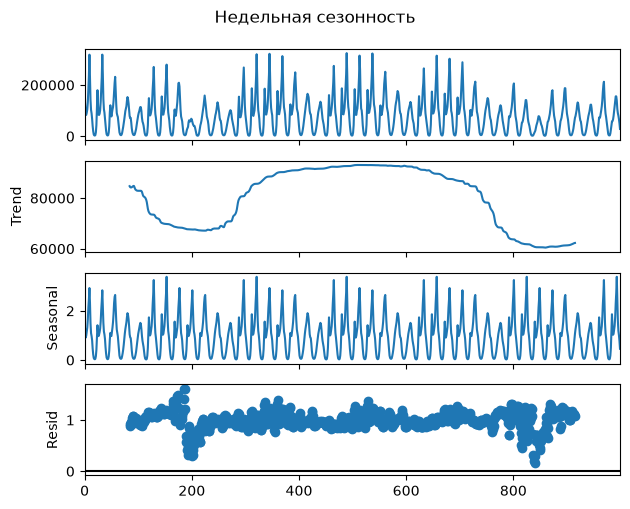

In [30]:
result = seasonal_decompose(series_subway, model='multiplicative', period=168)
fig = result.plot()
fig.suptitle("Недельная сезонность", y=1.05)
plt.show()

Мультипликативная модель декомпозиции с period=168 показывает тот же Trend, что и аддитивная версия (плавный рост загруженности с 65 до 100 тыс. и обратный спад), но Seasonal здесь выражена как коэффициент, колеблющийся в диапазоне примерно 0-3, а не в абсолютных величинах. Resid же в мультипликативной модели колеблется вокруг 1 более равномерно на большей части ряда, что говорит о лучшем соответствии модели данным по сравнению с аддитивной версией. Амплитуда недельных/суточных колебаний действительно растет пропорционально общему уровню тренда (в периоды высокой загруженности метро колебания больше по абсолютной величине, чем в периоды низкой загруженности)

При этом провалы в двух областях (около часов 200 и 800) тоже видны. В мультипликативной модели они проявляются как резкое падение Resid ниже 1, что даже нагляднее, чем в аддитивной модели, показывает масштаб аномалии: в эти дни фактический трафик составлял лишь 20-30% от ожидаемого по модели значения, а не просто демонстрировал абсолютное отклонение на фиксированную величину

* Преобразование Фурье

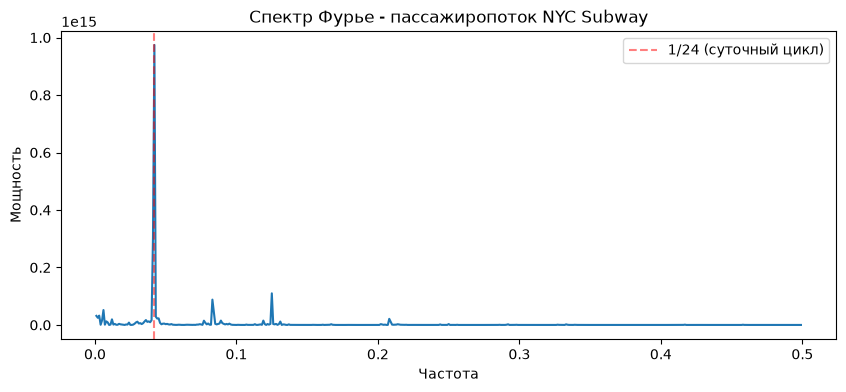

In [31]:
fft_vals = np.fft.fft(series_subway.values)
freqs = np.fft.fftfreq(len(series_subway))
power = np.abs(fft_vals)**2

plt.figure(figsize=(10,4))
plt.plot(freqs[freqs > 0], power[freqs > 0])
plt.axvline(1/24, color='red', linestyle='--', alpha=0.5, label='1/24 (суточный цикл)')
plt.xlabel("Частота")
plt.ylabel("Мощность")
plt.title("Спектр Фурье - пассажиропоток NYC Subway")
plt.legend()
plt.show()

Спектр Фурье содержит доминирующий пик на частоте 1/24 (суточный цикл), мощность которого на несколько порядков превышает фоновый шум. Дополнительные пики на частотах 2/24 и 3/24 - гармоники, отражающие двугорбую форму суточного профиля с двумя часами пик, утренним и вечерним

* Автокорреляционная функция

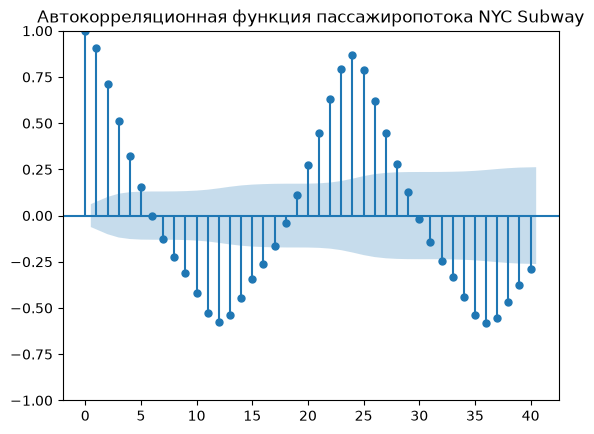

In [32]:
plot_acf(series_subway, lags=40)
plt.title("Автокорреляционная функция пассажиропотока NYC Subway")
plt.show()

In [33]:
from statsmodels.tsa.stattools import acf

acf_values = acf(series_subway, nlags=40)
peak_lag = np.argmax(acf_values[5:]) + 5  # ищем максимум, пропустив самое начало (lag 0-4 тривиально высокие)
print(f"Лаг с максимальной автокорреляцией (после lag=5): {peak_lag}, значение: {acf_values[peak_lag]:.3f}")

Лаг с максимальной автокорреляцией (после lag=5): 24, значение: 0.868


Видно ярко выраженную периодическую структуру. Расчет показывает максимум автокорреляции на lag=24 (значение ACF=0.868), что соответствует суточному циклу при почасовых данных. Это подтверждает наблюдение с сезонной декомпозиции и спектра Фурье: значение пассажиропотока в определенный час сильно и статистически значимо коррелирует со значением ровно сутки назад. На промежуточных лагах (примерно 10-15) наблюдается выраженная отрицательная корреляция. Значения в противофазе суточного цикла (час пик против ночного затишья)

*Теорема Такенса*

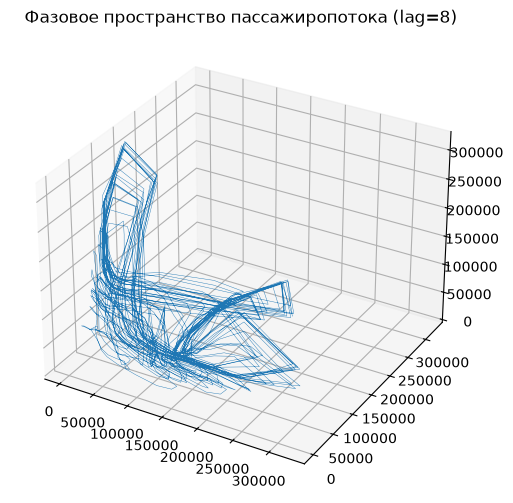

In [34]:
lag = 8  # Сдвиг в 8 часов покажет структуру внутри суток
embed_dim = 3
N = len(series_subway)
X = np.array([
    [series_subway.values[i], series_subway.values[i+lag], series_subway.values[i+2*lag]]
    for i in range(N - 2*lag)
])

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(projection='3d')
ax.plot(X[:,0], X[:,1], X[:,2], lw=0.3)
ax.set_title(f"Фазовое пространство пассажиропотока (lag={lag})");
plt.show()

Есть выраженная структурированность траектории: видны повторяющиеся, наложенные друг на друга пути. Это согласуется со всеми предыдущими результатами (сезонная декомпозиция, спектр Фурье, ACF) и подтверждает наличие детерминированной, предсказуемой структуры, а не случайного блуждания

Форма не идеально гладкая замкнутая петля: отражает, что день ото дня пиковые значения немного отличаются по величине

* Показатель Хёрста и размерность Хаусдорфа

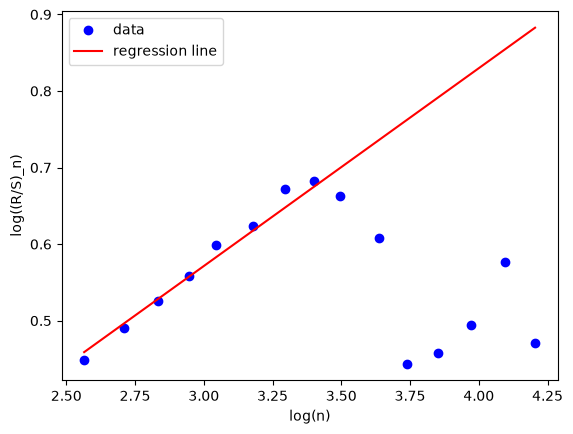

Показатель Хёрста: 0.758
Размерность Хаусдорфа: 1.242


In [35]:
H = nolds.hurst_rs(series_subway.values, debug_plot=True)
D_hausdorff = 2 - H

print(f"Показатель Хёрста: {H:.3f}")
print(f"Размерность Хаусдорфа: {D_hausdorff:.3f}")

H=0.758 указывает на персистентность ряда, согласуясь с высокими значениями ACF на лаге 24 и наличием доминирующей частоты на спектре Фурье. Размерность Хаусдорфа D=1.242 близка к эталону линейного тренда (D=1), что отражает структурированность и предсказуемость траектории пассажиропотока

Отметим, что на больших масштабах (log(n)>3.5, что соответствует окнам примерно 35-40 часов) точки данных систематически отклоняются от линии регрессии вниз. Это ожидаемо, так как на этих масштабах идет уже не столько суточная персистентность, сколько граница суточного цикла (после 24-48 часов структура ряда меняет характер - начинается новый цикл, а не продолжение тренда), что несколько искажает единую R/S-оценку для периодического процесса

* Показатель Ляпунова и энтропия Колмогорова-Синая

In [36]:
lyap = nolds.lyap_r(series_subway.values)
print(f"Показатель Ляпунова (старший): {lyap:.4f}")

ks_entropy = max(lyap, 0)
print(f"Энтропия Колмогорова-Синая (по теореме Песина): {ks_entropy:.4f}")

Показатель Ляпунова (старший): 0.0061
Энтропия Колмогорова-Синая (по теореме Песина): 0.0061


Показатель Ляпунова близок к нулю, что указывает на отсутствие хаотической динамики. Это согласуется с наблюдаемой на графике Такенса структурой (повторяющиеся, плотно наложенные траектории, а не расходящееся облако) и подтверждает, что высокая предсказуемость пассажиропотока, выявленная через ACF, Фурье и Хёрста, обусловлена не детерминированным хаосом, а периодической динамикой. Малое, но не строго отрицательное значение отражает наличие умеренного шума поверх устойчивого суточного цикла (день ото дня пиковые значения незначительно варьируются, как уже отмечалось при анализе R/S-графика и фазового портета)

* Энтропия перестановок

In [37]:
import antropy as ant

for order in [3, 4, 5, 6]:
    pe = ant.perm_entropy(series_subway.values, order=order, normalize=True)
    print(f"order={order}: Энтропия перестановок = {pe:.4f}")

order=3: Энтропия перестановок = 0.6557
order=4: Энтропия перестановок = 0.5301
order=5: Энтропия перестановок = 0.4667
order=6: Энтропия перестановок = 0.4233


1. Значение заметно отклоняется от максимума (1.0), что означает: не все 6 возможных вариантов взаимного порядка соседних значений равновероятны, некоторые паттерны (например, "монотонный рост" в утренние часы или "монотонное падение" ночью) встречаются заметно чаще других. Это прямое проявление предсказуемой, направленной локальной динамики ряда
2. Устойчивое снижение PE с ростом order. Чем длиннее анализируемое окно, тем более предсказуемым оказывается взаимный порядок значений внутри него. Локально (3 соседних часа) ряд может казаться менее предсказуемым из-за случайных колебаний внутри дня, но на более длинных окнах (5-6 часов подряд) начинает проявляться устойчивая суточная структура (стабильный рост к пику или стабильный спад к ночи), что резко снижает разнообразие встречающихся паттернов порядка

In [38]:
pe = ant.perm_entropy(series_subway.values, order=3, normalize=True)  # основное значение для таблицы

* Сводная таблица

In [39]:
results_subway = pd.DataFrame({
    "Ряд": ["NYC Subway ridership"],
    "ADF p-value": [adf_result[1]],
    "Shapiro p-value": [shapiro_p],
    "Hurst": [H],
    "Hausdorff dim": [D_hausdorff],
    "Lyapunov": [lyap],
    "KS entropy": [ks_entropy],
    "Permutation entropy": [pe],
})
results_subway

,Ряд,ADF p-value,Shapiro p-value,Hurst,Hausdorff dim,Lyapunov,KS entropy,Permutation entropy
0,NYC Subway ridership,0.32436,1.680347e-23,0.758432,1.241568,0.006148,0.006148,0.65572


Сезонная декомпозиция выявляет выраженную суточную (period=24) и недельную (period=168) периодичность с амплитудой, сопоставимой с исходным рядом; мультипликативная модель декомпозиции подходит лучше аддитивной, так как амплитуда колебаний растет пропорционально общему уровню трафика. Спектр Фурье показывает доминирующий пик на частоте 1/24 с гармониками на 2/24 и 3/24, отражающими двугорбую (утро + вечер) форму суточного профиля. Автокорреляционная функция демонстрирует точный максимум на лаге 24 (ACF=0.868). Реконструкция фазового пространства (теорема Такенса) показывает структурированную, циклически повторяющуюся траекторию

Практический вывод о предсказуемости: в отличие от доходностей Apple, пассажиропоток содержит статистически значимый и практически применимый предсказуемый сигнал: прошлые значения ряда (особенно с лагом 24 часа) дают существенную информацию о будущих значениях. Природа этой предсказуемости периодическая, а не хаотическая: низкий показатель Ляпунова в сочетании с высоким Хёрстом и структурированным фазовым портретом указывает на устойчивый циклический процесс с умеренным шумом, а не на детерминированный хаос

**Третий датасет**

*Fantasia Database (PhysioNet)* - записи ЭКГ в состоянии покоя (250 Гц, 120 минут), 40 испытуемых. Я взяла запись f1y01, канал ECG

In [40]:
import wfdb

# Fantasia Database на PhysioNet называется 'fantasia', записи именуются f1y01-f1y10 (young) и f1o01-f1o10 (old) для группы 1, и f2y/f2o для группы 2
FANTASIA_DIR = DATA_DIR / "fantasia"
if not (FANTASIA_DIR / "f1y01.dat").exists():
    # скачиваем запись с PhysioNet один раз, дальше читаем с диска
    wfdb.dl_database("fantasia", str(FANTASIA_DIR), records=["f1y01"], annotators=["ecg"])
record = wfdb.rdrecord(str(FANTASIA_DIR / "f1y01"))

print(f"Каналы: {record.sig_name}")
print(f"Частота дискретизации: {record.fs} Гц")
print(f"Длина записи: {record.p_signal.shape[0]} точек")

Каналы: ['RESP', 'ECG']
Частота дискретизации: 250 Гц
Длина записи: 1806271 точек


In [41]:
ecg_channel_idx = record.sig_name.index('ECG')
ecg_full = record.p_signal[:, ecg_channel_idx]

print(f"Полная длина сигнала ЭКГ: {len(ecg_full)} точек")

Полная длина сигнала ЭКГ: 1806271 точек


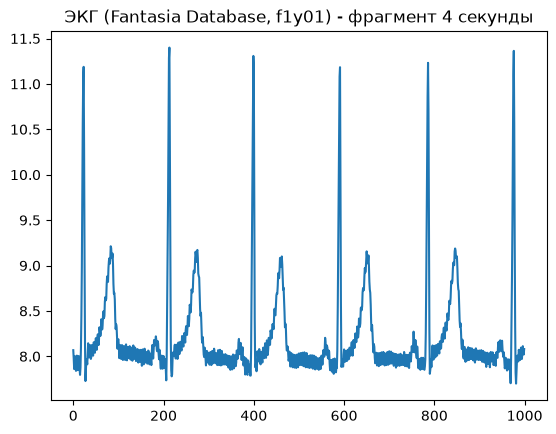

In [42]:
import pandas as pd

# Сдвинемся вглубь записи
start_idx = 60000  # пропускаем первые 240 секунд

ecg_series = pd.Series(ecg_full[start_idx:start_idx+1000]).reset_index(drop=True)
ecg_series.plot(title="ЭКГ (Fantasia Database, f1y01) - фрагмент 4 секунды");

In [43]:
duration_seconds = len(ecg_series) / record.fs
print(f"Длительность фрагмента: {duration_seconds} секунд")

Длительность фрагмента: 4.0 секунд


In [44]:
from scipy.signal import find_peaks

peaks, _ = find_peaks(ecg_series.values, height=10, distance=100)
print(f"Найдено пиков: {len(peaks)}")
print(f"Позиции пиков: {peaks}")

intervals = np.diff(peaks)
print(f"Интервалы между пиками (в точках): {intervals}")
print(f"Средний интервал: {intervals.mean():.1f} точек")
print(f"Соответствующая частота сердечных сокращений: {60 * 250 / intervals.mean():.1f} уд/мин")

Найдено пиков: 6
Позиции пиков: [ 23 213 399 591 786 976]
Интервалы между пиками (в точках): [190 186 192 195 190]
Средний интервал: 190.6 точек
Соответствующая частота сердечных сокращений: 78.7 уд/мин


ЭКГ демонстрирует визуально очевидную, регулярную периодическую структуру уже на коротком фрагменте (4 секунды, 6 полных кардиоциклов). Средний период сокращения составляет 190.6 точек (примерно 78.7 уд/мин), что задает естественный масштаб для последующей сезонной декомпозиции

*Тест на случайное блуждание*

In [45]:
adf_result = adfuller(ecg_series.values)

print(f"ADF statistic: {adf_result[0]:.3f}")
print(f"p-value: {adf_result[1]:.4f}")
print(f"Число использованных лагов: {adf_result[2]}")
print(f"Число наблюдений: {adf_result[3]}")
print(f"Критические значения: {adf_result[4]}")

ADF statistic: -6.012
p-value: 0.0000
Число использованных лагов: 20
Число наблюдений: 979
Критические значения: {'1%': np.float64(-3.4370471695043037), '5%': np.float64(-2.8644967585264784), '10%': np.float64(-2.5683443301882956)}


ADF-тест подтверждает стационарность ряда ЭКГ (p=0.0000, statistic=−6.012, многократно превышающий по модулю критическое значение 1% уровня значимости). Использование теста большого числа лагов (20) отражает сильную периодическую структуру сигнала, связанную с регулярностью кардиоцикла

*Проверка нормальности распределения*

In [46]:
shapiro_stat, shapiro_p = stats.shapiro(ecg_series.values)
print(f"Тест Шапиро-Уилка: statistic={shapiro_stat:.3f}, p-value={shapiro_p:.2e}")

Тест Шапиро-Уилка: statistic=0.603, p-value=6.90e-43


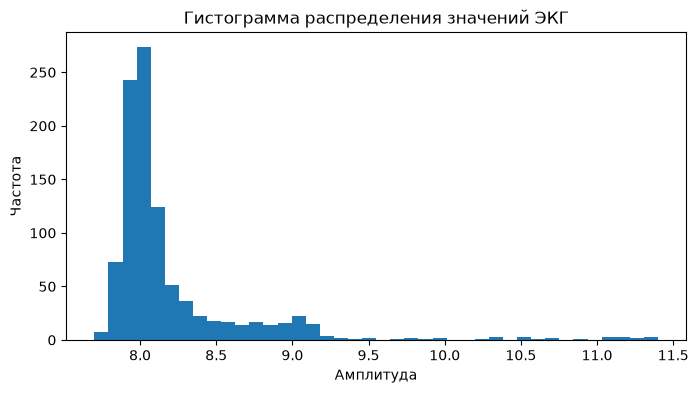

In [47]:
plt.figure(figsize=(8,4))
plt.hist(ecg_series.values, bins=40)
plt.title("Гистограмма распределения значений ЭКГ")
plt.xlabel("Амплитуда")
plt.ylabel("Частота")
plt.show()

Тест Шапиро-Уилка демонстрирует крайне сильное отклонение от нормального распределения: p-value практически равно нулю (6.90×10⁻⁴³), а статистика (0.603) заметно ниже, чем у двух предыдущих рядов. Это объясняется резко асимметричной формой кардиоцикла: сигнал большую часть времени находится на стабильном базовом уровне между ударами, тогда как узкие, но высокоамплитудные QRS-комплексы формируют редкие экстремальные значения. Такая структура создает сильно скошенное распределение с выраженным пиком у типичного (8.0) значения и тяжелым правым хвостом, далекое от гауссовской формы

* Сезонная декомпозиция

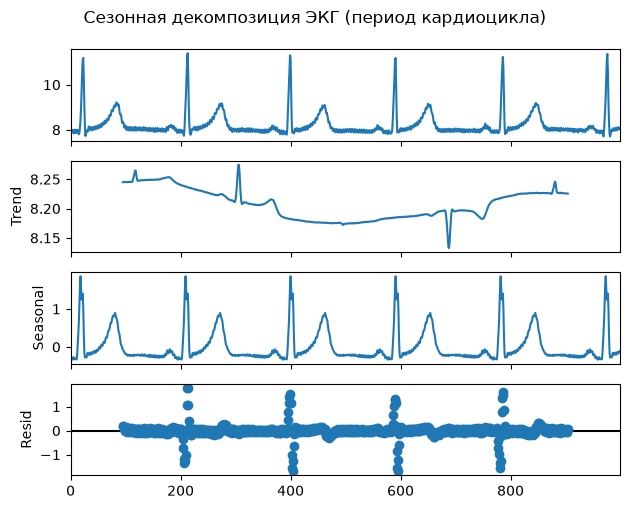

In [48]:
result = seasonal_decompose(ecg_series, model='additive', period=191)
fig = result.plot()
fig.suptitle("Сезонная декомпозиция ЭКГ (период кардиоцикла)", y=1.05)
plt.show()

Сезонная декомпозиция с физиологически обоснованным периодом (191 точка, определенным через автоматический поиск пиков) выявляет выраженную, доминирующую периодическую структуру: Seasonal-компонента почти повторяет форму исходного сигнала по амплитуде. Trend стабилен в узком диапазоне без выраженного долгосрочного дрейфа, согласуясь со стационарностью ряда по ADF-тесту. Всплески в Resid, приуроченные к моментам QRS-комплексов, отражают естественную вариабельность сердечного ритма (интервалы между ударами варьируются на несколько точек), из-за чего единая модель с фиксированным периодом не полностью улавливает точную форму каждого отдельного пика

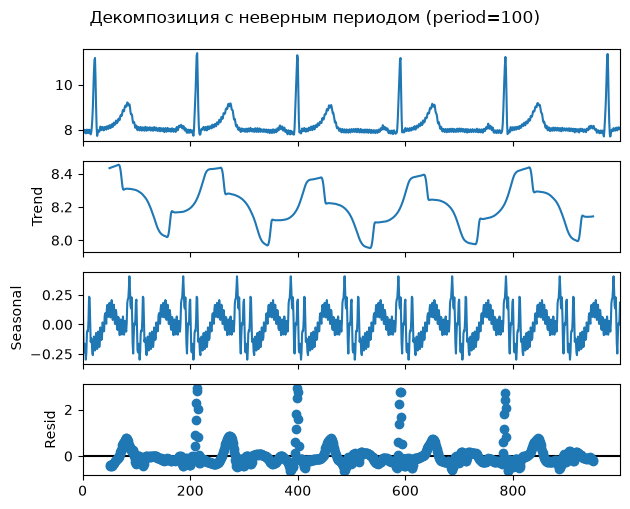

In [49]:
result_wrong = seasonal_decompose(ecg_series, model='additive', period=100)
fig = result_wrong.plot()
fig.suptitle("Декомпозиция с неверным периодом (period=100)", y=1.05)
plt.show()

Декомпозиция с намеренно неверным периодом (100 вместо физиологически точного 191) демонстрирует явную деградацию качества модели: амплитуда Seasonal-компоненты снизилась почти на порядок и потеряла характерную форму кардиоцикла, Trend приобрел несвойственную ему волнообразную структуру (переняв часть периодического сигнала, которую не смогла объяснить Seasonal), а амплитуда Resid выросла вдвое

* Преобразование Фурье

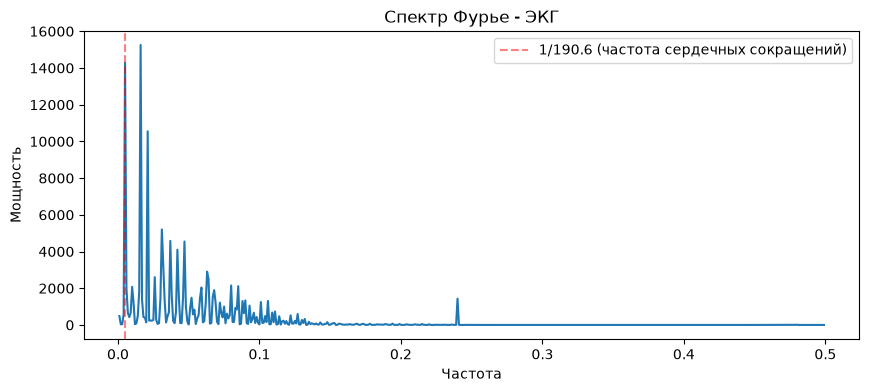

In [50]:
fft_vals = np.fft.fft(ecg_series.values)
freqs = np.fft.fftfreq(len(ecg_series))
power = np.abs(fft_vals)**2

plt.figure(figsize=(10,4))
plt.plot(freqs[freqs > 0], power[freqs > 0])
plt.axvline(1/190.6, color='red', linestyle='--', alpha=0.5, label='1/190.6 (частота сердечных сокращений)')
plt.xlabel("Частота")
plt.ylabel("Мощность")
plt.title("Спектр Фурье - ЭКГ")
plt.legend()
plt.show()

In [51]:
mask = (freqs > 0) & (freqs < 0.05)
peak_idx = np.argmax(power[mask])
peak_freq = freqs[mask][peak_idx]
print(f"Частота максимального пика: {peak_freq:.5f}")
print(f"Соответствующий период: {1/peak_freq:.1f} точек")
print(f"Ожидаемый период кардиоцикла: 190.6 точек")

Частота максимального пика: 0.01600
Соответствующий период: 62.5 точек
Ожидаемый период кардиоцикла: 190.6 точек


In [52]:
target_freq = 1/190.6
idx = np.argmin(np.abs(freqs - target_freq))
print(f"Мощность на частоте основного тона ({freqs[idx]:.5f}): {power[idx]:.1f}")
print(f"Мощность на частоте доминирующей гармоники (0.016): {power[np.argmin(np.abs(freqs - 0.016))]:.1f}")

Мощность на частоте основного тона (0.00500): 14278.4
Мощность на частоте доминирующей гармоники (0.016): 15255.1


Спектр Фурье ЭКГ содержит два сопоставимых по мощности выраженных пика: на частоте 0.005 (соответствует физиологическому периоду кардиоцикла 190.6 точек, мощность 14278) и на ее третьей гармонике, частоте 0.016 (мощность 15255, что на 7% выше основного тона). Присутствие столь мощной высшей гармоники объясняется резко несинусоидальной формой сигнала — острый, узкий QRS-комплекс требует существенного вклада высокочастотных составляющих для корректного спектрального представления, в отличие от плавных, близких к синусоиде процессов. Оба пика превышают фоновый уровень мощности на прочих частотах, что подтверждает сильную периодическую природу сигнала

* Автокорреляционная функция

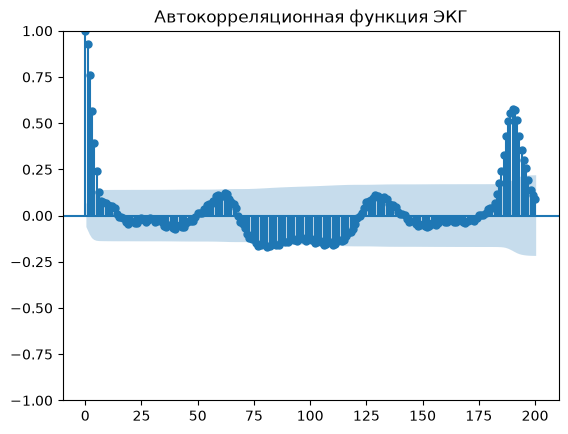

In [53]:
plot_acf(ecg_series, lags=200)
plt.title("Автокорреляционная функция ЭКГ")
plt.show()

ACF показывает явную периодическую структуру: помимо тривиального lag=0, виден большой положительный пик на лаге около 185-190 (значение примерно 0.57, выходит далеко за пределы доверительного интервала) - это точно соответствует физиологическому периоду кардиоцикла (190.6 точек, рассчитанному ранее через find_peaks). Значение в точности сердечного ритма прямо коррелирует со значением примерно на один удар назад

Есть еще два небольших положительных горба (на лагах 60 и 125), разделенных провалами в минус. Это связано с формой самого удара сердца - резкий пик сменяется более плавной волной, и это чередование форм внутри одного цикла тоже дает о себе знать на графике автокорреляции

*Теорема Такенса*

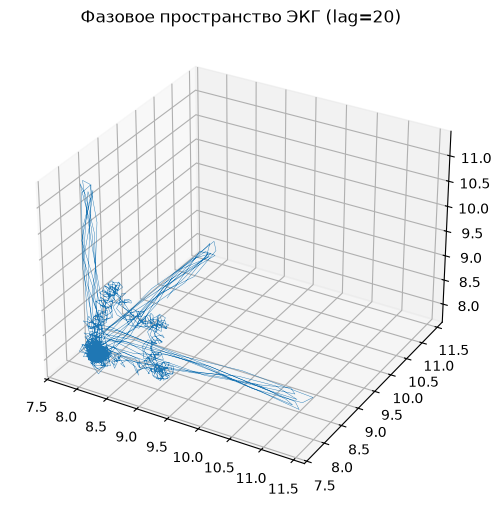

In [54]:
lag = 20  # Сдвиг примерно 1/10 периода кардиоцикла, чтобы раскрыть форму траектории внутри одного удара
embed_dim = 3
N = len(ecg_series)
X = np.array([
    [ecg_series.values[i], ecg_series.values[i+lag], ecg_series.values[i+2*lag]]
    for i in range(N - 2*lag)
])

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(projection='3d')
ax.plot(X[:,0], X[:,1], X[:,2], lw=0.3)
ax.set_title(f"Фазовое пространство ЭКГ (lag={lag})")
plt.show()

Реконструированное фазовое пространство ЭКГ демонстрирует четкую, узнаваемую структуру с несколькими характерными элементами: плотное скопление траекторий в нижнем левом углу, из которого расходятся несколько выраженных лучей, ведущих к удаленным точкам пространства. Такая форма типична для механизма сердечного цикла (медленное восстановление между ударами, резкое электрическое возбуждение при сокращении)

* Показатель Хёрста и размерность Хаусдорфа

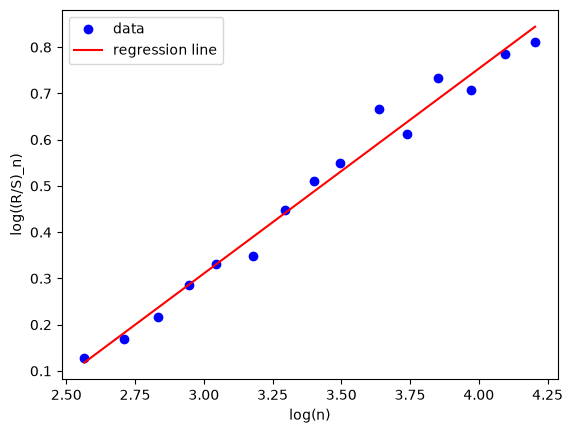

Показатель Хёрста: 0.943
Размерность Хаусдорфа: 1.057


In [55]:
H = nolds.hurst_rs(ecg_series.values, debug_plot=True)
D_hausdorff = 2 - H

print(f"Показатель Хёрста: {H:.3f}")
print(f"Размерность Хаусдорфа: {D_hausdorff:.3f}")

H=0.943 самое высокое значение персистентности среди всех 3х рассмотренных рядов, что отражает исключительно устойчивую, предсказуемую структуру ЭКГ на исследуемом масштабе. Размерность Хаусдорфа D=1.057 практически совпадает с эталоном линейного тренда. В отличие от предыдущих R/S-графиков, точки здесь ложатся на линию регрессии почти идеально на всем диапазоне масштабов, без излома

* Показатель Ляпунова и энтропия Колмогорова-Синая

In [56]:
lyap = nolds.lyap_r(ecg_series.values)
print(f"Показатель Ляпунова (старший): {lyap:.4f}")

ks_entropy = max(lyap, 0)
print(f"Энтропия Колмогорова-Синая (по теореме Песина): {ks_entropy:.4f}")

Показатель Ляпунова (старший): -0.0100
Энтропия Колмогорова-Синая (по теореме Песина): 0.0000


Показатель Ляпунова ЭКГ единственный из 3х рассмотренных рядов с отрицательным значением. Это указывает на сходящуюся, устойчивую динамику: близкие фазовые траектории со временем сближаются, а не расходятся, что характерно для систем с устойчивым предельным циклом. Соответствующая KS-энтропия равна нулю, что для детерминированной интерпретации означало бы отсутствие потери информации о состоянии системы - сигнал полностью определяется своей циклической структурой без накопления неопределенности. Физиологически это согласуется с активной саморегуляцией сердечного ритма. Система не просто периодична, но и устойчиво возвращается к своему характерному циклу даже при небольших отклонениях отдельных ударов (естественная вариабельность сердечного ритма)

* Энтропия перестановок

In [57]:
for order in [3, 4, 5, 6]:
    pe = ant.perm_entropy(ecg_series.values, order=order, normalize=True)
    print(f"order={order}: Энтропия перестановок = {pe:.4f}")

order=3: Энтропия перестановок = 0.9425
order=4: Энтропия перестановок = 0.8519
order=5: Энтропия перестановок = 0.8225
order=6: Энтропия перестановок = 0.7652


Энтропия перестановок ЭКГ занимает промежуточное положение между Apple и метро на уровне order=3 (0.9425), что на первый взгляд противоречит выводам по Хёрсту и Ляпунову о высокой предсказуемости сигнала. Это объясняется масштабом анализа: при частоте дискретизации 250 Гц три соседних точки покрывают лишь 12 мс, на таком мелком масштабе PE преимущественно улавливает мелкомасштабный шум внутри относительно однородных участков сигнала (базовая линия), а не макроструктуру кардиоцикла (190 точек). PE устойчиво снижается с ростом order (до 0.7652 при order=6), поскольку более длинные окна начинают захватывать содержательную структуру формы сигнала. Это подчеркивает важность выбора масштаба анализа (order) относительно частоты дискретизации при интерпретации энтропии перестановок — разные метрики предсказуемости чувствительны к разным временным масштабам одного и того же процесса

In [58]:
pe = ant.perm_entropy(ecg_series.values, order=3, normalize=True)  # основное значение для таблицы

* Сводная таблица

In [59]:
results_ecg = pd.DataFrame({
    "Ряд": ["ECG (Fantasia f1y01)"],
    "ADF p-value": [adf_result[1]],
    "Shapiro p-value": [shapiro_p],
    "Hurst": [H],
    "Hausdorff dim": [D_hausdorff],
    "Lyapunov": [lyap],
    "KS entropy": [ks_entropy],
    "Permutation entropy": [pe],
})
results_ecg

,Ряд,ADF p-value,Shapiro p-value,Hurst,Hausdorff dim,Lyapunov,KS entropy,Permutation entropy
0,ECG (Fantasia f1y01),1.568727e-07,6.896569e-43,0.943049,1.056951,-0.009981,0,0.94248


Сезонная декомпозиция с физиологически точным периодом (191 точка, определенным через анализ пиков сигнала) выявляет выраженную, периодическую структуру, сопоставимую по амплитуде с самим сигналом; неверный период (например, 100) заметно ухудшает качество модели, что подтверждает необходимость точного расчета периода для физиологических рядов. Спектр Фурье показывает два сопоставимых по мощности пика на частоте основного тона (1/190.6) и на ее третьей гармонике, что отражает острую форму QRS-комплекса. Автокорреляционная функция демонстрирует выраженный максимум на лаге примерно 188 (ACF=0.57), совпадающий с периодом кардиоцикла, а также промежуточную колебательную структуру, отражающую внутреннюю фазовую форму одного удара. Реконструкция фазового пространства (теорема Такенса) выявляет характерную структуру колебаний: плотное ядро траекторий (фаза покоя между ударами) с расходящимися направленными лучами (резкий скачок).

Практический вывод о предсказуемости: ЭКГ демонстрирует самую высокую предсказуемость среди всех 3х рассмотренных рядов: показатель Хёрста (0.943) близок к максимуму, а показатель Ляпунова, в отличие от двух других датасетов, отрицателен (−0.0100), что указывает на устойчивый притягивающий предельный цикл: близкие траектории сходятся друг к другу, а не расходятся. Единственное отклонение от идеальной картины - энтропия перестановок при малых order (0.9425 при order=3) заметно выше, чем у метро, что объясняется мелким временным масштабом анализа (12 мс при 250 Гц) относительно длительности всего кардиоцикла

**ИТОГ**

In [60]:
final_results = pd.concat([results, results_subway, results_ecg], ignore_index=True)
final_results

,Ряд,ADF p-value,Shapiro p-value,Hurst,Hausdorff dim,Lyapunov,KS entropy,Permutation entropy
0,Apple returns,0.000000e+00,1.004108e-11,0.533396,1.466604,0.008695,0.008695,0.999675
1,NYC Subway ridership,3.243604e-01,1.680347e-23,0.758432,1.241568,0.006148,0.006148,0.655720
2,ECG (Fantasia f1y01),1.568727e-07,6.896569e-43,0.943049,1.056951,-0.009981,0.000000,0.942480


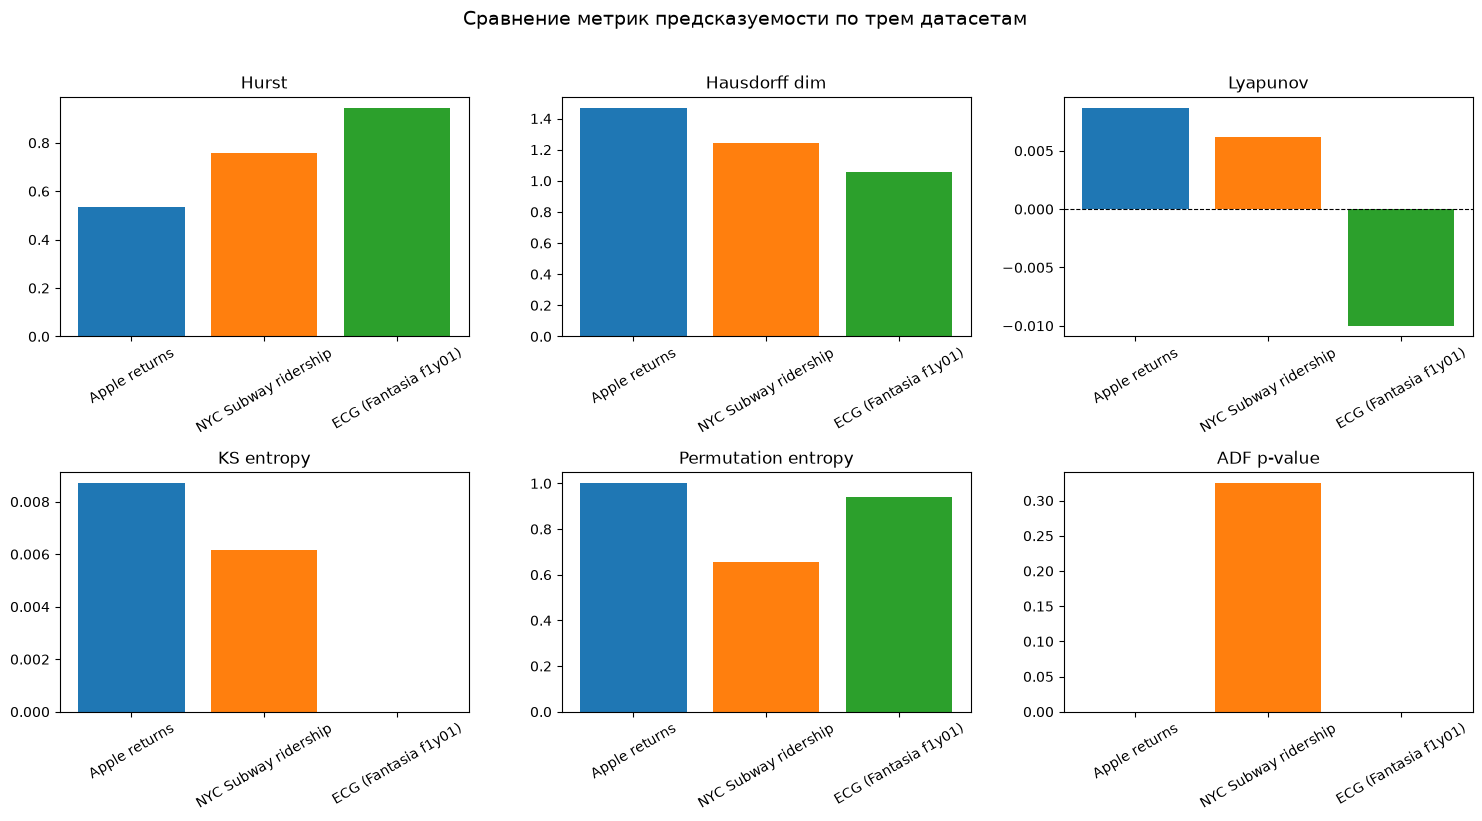

In [61]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

metrics = ["Hurst", "Hausdorff dim", "Lyapunov", "KS entropy", "Permutation entropy", "ADF p-value"]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, metric in enumerate(metrics):
    axes[i].bar(final_results["Ряд"], final_results[metric], color=colors)
    axes[i].set_title(metric)
    axes[i].tick_params(axis='x', rotation=30)
    if metric == "Lyapunov":
        axes[i].axhline(0, color='black', linewidth=0.8, linestyle='--')

plt.suptitle("Сравнение метрик предсказуемости по трем датасетам", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Три ряда демонстрируют три разных режима предсказуемости, выстраивающиеся в своеобразный порядок по метрикам (Хёрст растет 0.53 -> 0.76 -> 0.94, Ляпунов падает от слабо положительного к отрицательному, Хаусдорфова размерность снижается 1.47 -> 1.24 -> 1.06), то есть от истинно случайного процесса (финансовый рынок) через периодический с шумом (антропогенная система с поведенческой цикличностью) к детерминированно-устойчивому (биологическая саморегулируемая система)